# EDA: Default of Credit Card Clients

Exploración rápida del dataset de actividad-1, para informar dos decisiones de actividad-2:
1. Qué variables poner en `configs/features.yaml` -> `CUSTOM`.
2. Si conviene escalar las variables de montos antes de entrenar.

No es un EDA exhaustivo -- ver `../../actividad-1/docs/diccionario-datos.md` para el detalle de cada columna.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

RUTA_DATOS = "../../actividad-1/data/credit_card_default.csv"
OBJETIVO = "default.payment.next.month"

df = pd.read_csv(RUTA_DATOS).drop(columns=["ID"])
df.shape

(30000, 24)

## 1. Forma general, tipos y nulos

In [2]:
print("Filas:", len(df), "- Columnas:", df.shape[1])
print("Nulos totales:", df.isnull().sum().sum())
df.dtypes

Filas: 30000 - Columnas: 24
Nulos totales: 0


LIMIT_BAL                     float64
SEX                             int64
EDUCATION                       int64
MARRIAGE                        int64
AGE                             int64
PAY_0                           int64
PAY_2                           int64
PAY_3                           int64
PAY_4                           int64
PAY_5                           int64
PAY_6                           int64
BILL_AMT1                     float64
BILL_AMT2                     float64
BILL_AMT3                     float64
BILL_AMT4                     float64
BILL_AMT5                     float64
BILL_AMT6                     float64
PAY_AMT1                      float64
PAY_AMT2                      float64
PAY_AMT3                      float64
PAY_AMT4                      float64
PAY_AMT5                      float64
PAY_AMT6                      float64
default.payment.next.month      int64
dtype: object

## 2. Distribución del target

default.payment.next.month
0    0.779
1    0.221
Name: proportion, dtype: float64


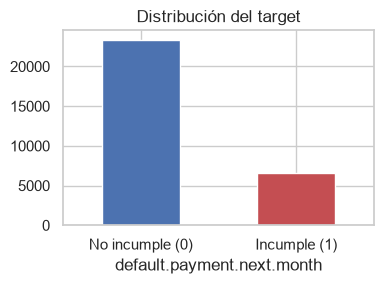

In [3]:
print(df[OBJETIVO].value_counts(normalize=True).round(3))

fig, ax = plt.subplots(figsize=(4, 3))
df[OBJETIVO].value_counts().sort_index().plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["No incumple (0)", "Incumple (1)"], rotation=0)
ax.set_title("Distribución del target")
plt.tight_layout()
plt.show()

## 3. Correlación de cada variable numérica con el target

In [4]:
numericas = df.drop(columns=[OBJETIVO]).select_dtypes(include="number").columns
correlaciones = df[numericas].corrwith(df[OBJETIVO]).sort_values(key=abs, ascending=False)
correlaciones

PAY_0        0.324794
PAY_2        0.263551
PAY_3        0.235253
PAY_4        0.216614
PAY_5        0.204149
PAY_6        0.186866
LIMIT_BAL   -0.153520
PAY_AMT1    -0.072929
PAY_AMT2    -0.058579
PAY_AMT4    -0.056827
PAY_AMT3    -0.056250
PAY_AMT5    -0.055124
PAY_AMT6    -0.053183
SEX         -0.039961
EDUCATION    0.028006
MARRIAGE    -0.024339
BILL_AMT1   -0.019644
BILL_AMT2   -0.014193
BILL_AMT3   -0.014076
AGE          0.013890
BILL_AMT4   -0.010156
BILL_AMT5   -0.006760
BILL_AMT6   -0.005372
dtype: float64

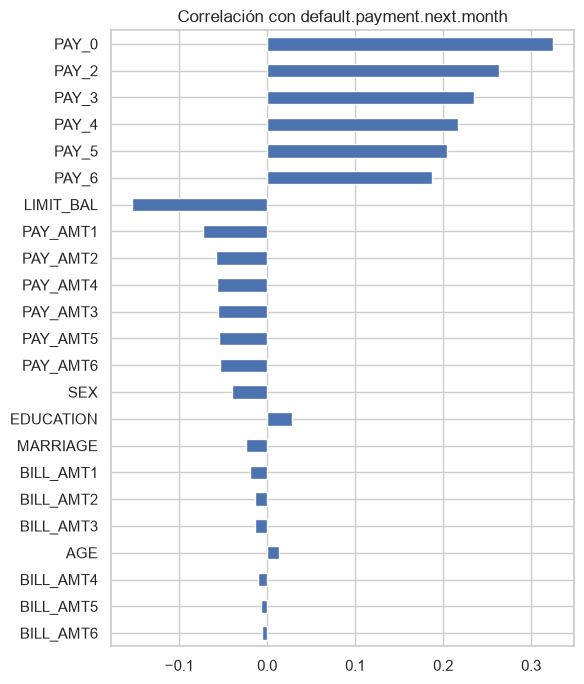

In [5]:
fig, ax = plt.subplots(figsize=(6, 7))
correlaciones.plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Correlación con default.payment.next.month")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 4. Outliers en montos (BILL_AMT*, PAY_AMT*)

In [6]:
columnas_monto = [c for c in df.columns if c.startswith("BILL_AMT") or c.startswith("PAY_AMT")] + ["LIMIT_BAL"]
df[columnas_monto].describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
BILL_AMT1,51223.330900,73635.860576,-165580.0,22381.5,964511.0
BILL_AMT2,49179.075167,71173.768783,-69777.0,21200.0,983931.0
BILL_AMT3,47013.154800,69349.387427,-157264.0,20088.5,1664089.0
BILL_AMT4,43262.948967,64332.856134,-170000.0,19052.0,891586.0
BILL_AMT5,40311.400967,60797.155770,-81334.0,18104.5,927171.0
BILL_AMT6,38871.760400,59554.107537,-339603.0,17071.0,961664.0
PAY_AMT1,5663.580500,16563.280354,0.0,2100.0,873552.0
PAY_AMT2,5921.163500,23040.870402,0.0,2009.0,1684259.0
PAY_AMT3,5225.681500,17606.961470,0.0,1800.0,896040.0
PAY_AMT4,4826.076867,15666.159744,0.0,1500.0,621000.0


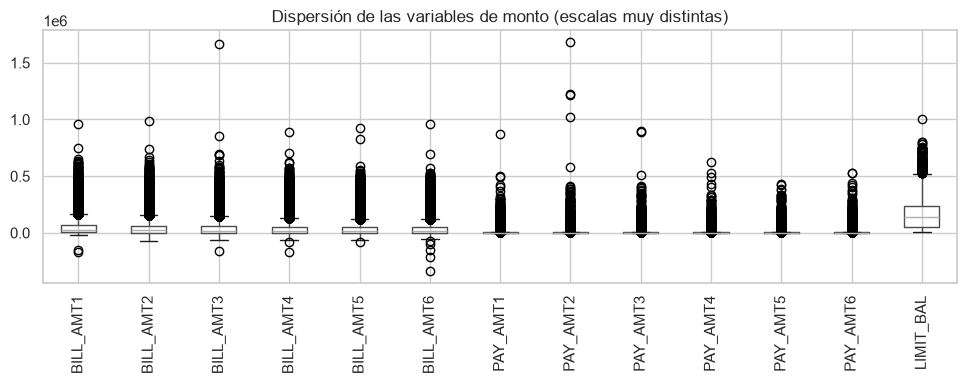

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
df[columnas_monto].boxplot(ax=ax, rot=90)
ax.set_title("Dispersión de las variables de monto (escalas muy distintas)")
plt.tight_layout()
plt.show()

## 5. Variables categóricas vs. tasa de incumplimiento

In [8]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"--- {col} ---")
    print(df.groupby(col)[OBJETIVO].agg(["mean", "count"]).round(3))
    print()

--- SEX ---
      mean  count
SEX              
1    0.242  11888
2    0.208  18112

--- EDUCATION ---
            mean  count
EDUCATION              
0          0.000     14
1          0.192  10585
2          0.237  14030
3          0.252   4917
4          0.057    123
5          0.064    280
6          0.157     51

--- MARRIAGE ---
           mean  count
MARRIAGE              
0         0.093     54
1         0.235  13659
2         0.209  15964
3         0.260    323



## Conclusiones

- **Variables mas correlacionadas con el target:** el historial de pago domina por completo -- `PAY_0` (0.32), `PAY_2` (0.26), `PAY_3` (0.24), bajando gradualmente hasta `PAY_6` (0.19). Despues, `LIMIT_BAL` (-0.15, a mayor cupo, menor incumplimiento). Los montos pagados (`PAY_AMT1`-`6`) tienen correlacion debil (-0.05 a -0.07). Los montos facturados (`BILL_AMT1`-`6`) son casi irrelevantes solos (|r| < 0.02). Las variables demograficas (`SEX`, `EDUCATION`, `MARRIAGE`, `AGE`) tambien son debiles de forma individual.

- **Decision para `CUSTOM` en `features.yaml`:** se confirma el set provisional del `PLAN.md` (`LIMIT_BAL` + `PAY_0`..`PAY_6`) -- son exactamente las 7 variables con mayor correlacion real. No se agregan `BILL_AMT*` porque aportan poca señal individual.

- **¿Escalar features?** Si, hace falta. `BILL_AMT*`/`LIMIT_BAL` llegan a cientos de miles (max ~1.6M), mientras `PAY_0`..`PAY_6` van de -2 a 8 y `SEX`/`EDUCATION` son 1-6. Sin escalar, un modelo lineal (regresion logistica) le da peso desproporcionado a las columnas de montos solo por su magnitud -- de ahi el `ConvergenceWarning` que vimos en actividad 1. El Modelo 1 (logistic regression) debe llevar `StandardScaler` en el pipeline.

- **Variables categoricas:**
  - `SEX`: los hombres (1) incumplen mas (24.2%) que las mujeres (2) (20.8%) -- diferencia real pero moderada.
  - `EDUCATION`: bachillerato (3) tiene la tasa mas alta entre categorias confiables (25.2%), posgrado (1) la mas baja (19.2%). Las categorias `0`/`5`/`6` tienen muy pocas filas (14, 280, 51) y tasas erraticas (ej. `0` da 0% con solo 14 filas) -- confirma que agruparlas en "otros" (como ya hace `src/datos.py` de actividad-1) es la decision correcta, no son confiables por separado.
  - `MARRIAGE`: "otros" (3) tiene la tasa mas alta (26%), soltero (2) la mas baja (20.9%). La categoria `0` (54 filas, 9.3%) tambien es poco confiable por tamaño -- mismo razonamiento, se agrupa.